# 04 - Evaluate the models

Rebuild the tuned models from notebook 03, combine Random Forest and Gradient Boosting, and compare all four models on the held-out test sessions. Load the prepared datasets exported by notebook 02. Results and charts are displayed here.

## 4.1 Prepare the data and rebuild the models

Load `data/processed/train.csv` from notebook 02. Load the exported test data only at final evaluation.

Use the settings selected in notebook 03: Logistic Regression uses C=0.1 with log-transformed counts and durations; Random Forest uses 200 trees, minimum leaf size 4 and square-root feature sampling; Gradient Boosting uses 200 stages, learning rate 0.05 and depth 3. These are the completed study's fixed choices.

All models one-hot encode categories, keep Weekend as 0/1 and exclude PageValues. Only Logistic Regression scales numeric values.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

project_folder = Path.cwd()
pd.set_option('display.max_columns', 30)

# Keep one numerical thread so timing conditions are comparable across models.
import os
for setting in ['OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS']:
    os.environ[setting] = '1'
from threadpoolctl import threadpool_limits
thread_limits = threadpool_limits(limits=1)
from time import perf_counter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_validate, cross_val_predict, StratifiedKFold
from sklearn.metrics import average_precision_score, brier_score_loss, precision_score, recall_score

nominal_columns = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType']
skewed_columns = ['Administrative', 'Administrative_Duration', 'Informational',
                  'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration']

import matplotlib.pyplot as plt
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

In [2]:
training_data = pd.read_csv(project_folder / 'data' / 'processed' / 'train.csv',
                            float_precision='round_trip')
training_features = training_data.drop(columns=['Revenue', 'PageValues'])
training_target = training_data['Revenue']
validation_folds = list(StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42).split(training_features, training_target))
print('Training sessions:', len(training_data))
print('Purchase proportion:', training_target.mean())

Training sessions: 9764
Purchase proportion: 0.15628840639082342


C:\Users\ongji\AppData\Local\Temp\ipykernel_22260\1286698480.py:1: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  training_data = pd.read_csv(project_folder / 'data' / 'processed' / 'train.csv',


In [3]:
def log_counts_and_durations(data):
    result = data.copy()
    result[skewed_columns] = np.log1p(result[skewed_columns])
    return result

def make_preprocessor(scale_numeric=False):
    numeric_columns = skewed_columns + ['BounceRates', 'ExitRates', 'SpecialDay']
    numeric_step = StandardScaler() if scale_numeric else 'passthrough'
    return ColumnTransformer([
        ('nominal', OneHotEncoder(handle_unknown='ignore', sparse_output=False), nominal_columns),
        ('numeric', numeric_step, numeric_columns),
        ('binary', 'passthrough', ['Weekend'])], remainder='drop')

In [4]:
lr_pipeline = Pipeline([
    ('features', FunctionTransformer(log_counts_and_durations)),
    ('preprocess', make_preprocessor(scale_numeric=True)),
    ('model', LogisticRegression(C=0.1, max_iter=2000, solver='lbfgs', random_state=42))])
rf_pipeline = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', RandomForestClassifier(n_estimators=200, min_samples_leaf=4,
                                    max_features='sqrt', random_state=42, n_jobs=1))])
gb_pipeline = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                                        max_depth=3, random_state=42))])
models = {'LogisticRegression': lr_pipeline, 'RandomForest': rf_pipeline,
          'GradientBoosting': gb_pipeline}

## 4.2 Combine Random Forest and Gradient Boosting

These models ranked first and second by training CV AP in notebook 03. Equal soft voting averages their two purchase scores. Check the combined model on the same five training folds before using the test set.

In [5]:
MEMBERS = ['RandomForest', 'GradientBoosting']
STRONGEST_BASE = 'RandomForest'

In [6]:
models['SoftVoting'] = VotingClassifier(
    estimators=[('RandomForest', clone(models['RandomForest'])),
                ('GradientBoosting', clone(models['GradientBoosting']))],
    voting='soft', weights=[1, 1], n_jobs=1)

cv_results = cross_validate(
    models['SoftVoting'], training_features, training_target, cv=validation_folds,
    scoring='average_precision', return_train_score=True, n_jobs=1, error_score='raise')
ensemble_validation = {
    'mean_ap': float(cv_results['test_score'].mean()),
    'sd_ap': float(cv_results['test_score'].std(ddof=1)),
    'train_ap': float(cv_results['train_score'].mean())}
for fold_number, score in enumerate(cv_results['test_score']):
    ensemble_validation[f'fold_{fold_number}_ap'] = score
display(pd.Series(ensemble_validation, name='Ensemble validation'))

mean_ap      0.382313
sd_ap        0.031214
train_ap     0.710887
fold_0_ap    0.379547
fold_1_ap    0.335055
fold_2_ap    0.408393
fold_3_ap    0.412852
fold_4_ap    0.375717
Name: Ensemble validation, dtype: float64

### Check whether the models make different errors
Each out-of-fold score comes from a model fitted without that training row. The correlation shows how similarly the two models rank sessions. The error counts show where their 0.50 decisions agree or differ. These are training checks, not test results.

In [7]:
out_of_fold_scores = {}
for model_name in MEMBERS:
    out_of_fold_scores[model_name] = cross_val_predict(
        models[model_name], training_features, training_target,
        cv=validation_folds, method='predict_proba', n_jobs=1)[:, 1]
forest_scores = out_of_fold_scores['RandomForest']
boosting_scores = out_of_fold_scores['GradientBoosting']
forest_wrong = (forest_scores >= 0.5) != training_target.to_numpy()
boosting_wrong = (boosting_scores >= 0.5) != training_target.to_numpy()
diversity = {
    'probability_correlation': float(np.corrcoef(forest_scores, boosting_scores)[0, 1]),
    'both_wrong': int((forest_wrong & boosting_wrong).sum()),
    'only_first_wrong': int((forest_wrong & ~boosting_wrong).sum()),
    'only_second_wrong': int((~forest_wrong & boosting_wrong).sum()),
    'RandomForest_brier': float(brier_score_loss(training_target, forest_scores)),
    'GradientBoosting_brier': float(brier_score_loss(training_target, boosting_scores))}
display(pd.Series(diversity, name='Training OOF comparison'))

probability_correlation       0.921445
both_wrong                 1424.000000
only_first_wrong             88.000000
only_second_wrong            90.000000
RandomForest_brier            0.114385
GradientBoosting_brier        0.115250
Name: Training OOF comparison, dtype: float64

## 4.3 Set the evaluation rules

Use a purchase-score threshold of 0.50 for class predictions. Compare the ensemble with Random Forest using 2,000 bootstrap samples and seed 42. For permutation importance, shuffle each input five times with seed 42. These rules stay fixed when we view test performance.

In [8]:
THRESHOLD = 0.50
BOOTSTRAP_SAMPLES = 2000
PERMUTATION_REPEATS = 5
RANDOM_SEED = 42

## 4.4 Fit the models and compare test results

Fit each model on all training sessions, then predict the same held-out test sessions. A score of at least 0.50 counts as a predicted purchase.

- AP measures how well purchases rank near the top.
- ROC-AUC measures how often a purchase ranks above a non-purchase.
- Accuracy is the fraction of all sessions classified correctly.
- Purchase precision is the fraction of predicted purchases that actually purchased.
- Purchase recall is the fraction of actual purchases found.
- F1 balances purchase precision and recall.

Fit time measures final training; prediction time is the median of five test batches. Tuning time is shown in notebook 03.

In [9]:
test_data = pd.read_csv(project_folder / 'data' / 'processed' / 'test.csv',
                        float_precision='round_trip')
test_features = test_data.drop(columns=['Revenue', 'PageValues'])
test_target = test_data['Revenue']
metric_rows = []
test_scores = {}
for model_name, model in models.items():
    print('Final fit and evaluation:', model_name, flush=True)
    start_time = perf_counter()
    model.fit(training_features, training_target)
    fit_seconds = perf_counter() - start_time

    prediction_times = []
    for repeat in range(5):
        start_time = perf_counter()
        purchase_scores = model.predict_proba(test_features)[:, 1]
        prediction_times.append(perf_counter() - start_time)
    test_scores[model_name] = purchase_scores
    predicted_labels = purchase_scores >= THRESHOLD
    tn, fp, fn, tp = confusion_matrix(test_target, predicted_labels).ravel()
    training_scores = model.predict_proba(training_features)[:, 1]
    metric_rows.append({
        'model': model_name,
        'test_ap': average_precision_score(test_target, purchase_scores),
        'roc_auc': roc_auc_score(test_target, purchase_scores),
        'accuracy': accuracy_score(test_target, predicted_labels),
        'purchase_precision': precision_score(test_target, predicted_labels, zero_division=0),
        'purchase_recall': recall_score(test_target, predicted_labels),
        'purchase_f1': f1_score(test_target, predicted_labels),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
        'full_train_ap': average_precision_score(training_target, training_scores),
        'fit_seconds': fit_seconds,
        'predict_seconds_median': float(np.median(prediction_times))})

final_comparison = pd.DataFrame(metric_rows)
display(final_comparison)

Final fit and evaluation: LogisticRegression


Final fit and evaluation: RandomForest


C:\Users\ongji\AppData\Local\Temp\ipykernel_22260\4063534709.py:1: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  test_data = pd.read_csv(project_folder / 'data' / 'processed' / 'test.csv',


Final fit and evaluation: GradientBoosting


Final fit and evaluation: SoftVoting


,model,test_ap,roc_auc,accuracy,purchase_precision,purchase_recall,purchase_f1,tn,fp,fn,tp,full_train_ap,fit_seconds,predict_seconds_median
0,LogisticRegression,0.341531,0.764015,0.843097,0.478261,0.028796,0.054321,2047,12,371,11,0.356585,0.085176,0.013533
1,RandomForest,0.382880,0.787850,0.843097,0.487805,0.052356,0.094563,2038,21,362,20,0.863403,2.951401,0.121332
2,GradientBoosting,0.352932,0.786963,0.839410,0.410714,0.060209,0.105023,2026,33,359,23,0.495379,6.904458,0.019631
3,SoftVoting,0.369281,0.791387,0.839000,0.372093,0.041885,0.075294,2032,27,366,16,0.696747,10.006290,0.142510


## 4.5 Plot precision and recall

As the score threshold falls, the models identify more purchases but may also flag more non-purchases. The curves show this trade-off. The dashed line is the test purchase proportion, used as the no-skill AP reference.

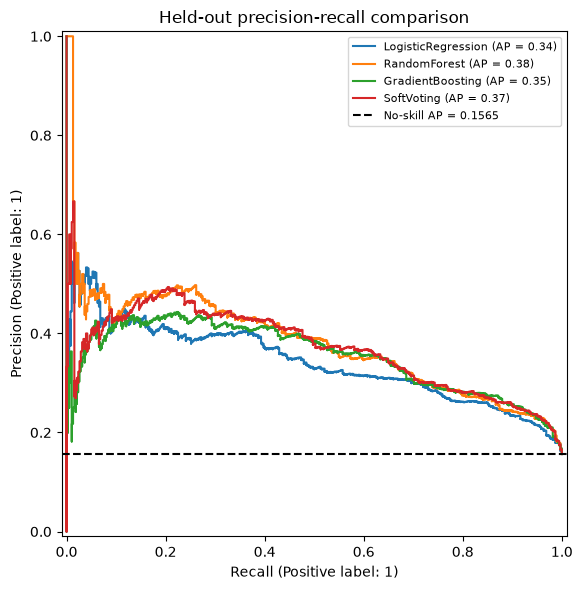

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
for model_name in models:
    PrecisionRecallDisplay.from_predictions(test_target, test_scores[model_name], name=model_name, ax=ax)
ax.axhline(test_target.mean(), linestyle='--', color='black', label=f'No-skill AP = {test_target.mean():.4f}')
ax.set_title('Held-out precision-recall comparison')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 4.6 Confusion matrices
Rows are actual outcomes; columns are predictions. The purchase row shows found purchases and missed purchases at threshold 0.50.

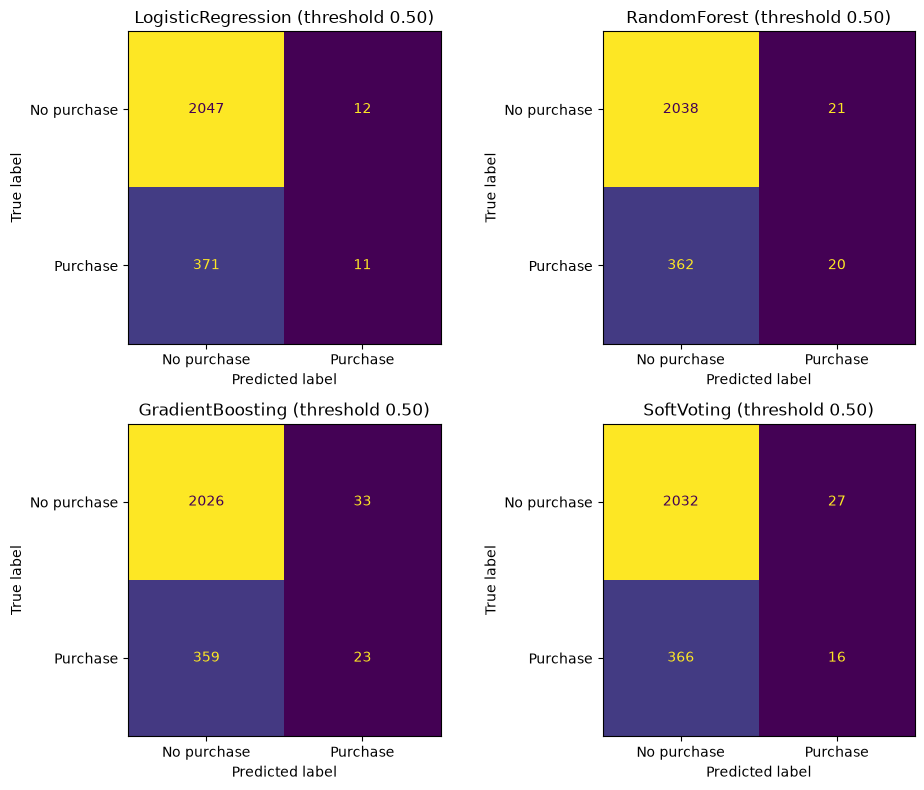

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, model_name in zip(axes.flat, models):
    predicted_labels = test_scores[model_name] >= THRESHOLD
    ConfusionMatrixDisplay.from_predictions(
        test_target, predicted_labels, display_labels=['No purchase', 'Purchase'], ax=ax, colorbar=False)
    ax.set_title(model_name + ' (threshold 0.50)')
fig.tight_layout()
plt.show()

## 4.7 Paired bootstrap interval
Resample the same test sessions for both models, then compare their AP scores. Repeat 2,000 times with seed 42. The middle 95% gives a percentile interval for ensemble AP minus Random Forest AP. Models stay fitted: this does not measure uncertainty from retraining or model selection.

In [12]:
random_generator = np.random.default_rng(RANDOM_SEED)
ap_differences, skipped_samples = [], 0
for _ in range(BOOTSTRAP_SAMPLES):
    sample_rows = random_generator.integers(0, len(test_target), len(test_target))
    if test_target.iloc[sample_rows].nunique() != 2:
        skipped_samples += 1
        continue
    ap_differences.append(average_precision_score(test_target.iloc[sample_rows], test_scores['SoftVoting'][sample_rows]) -
                       average_precision_score(test_target.iloc[sample_rows], test_scores[STRONGEST_BASE][sample_rows]))
observed_difference = average_precision_score(test_target, test_scores['SoftVoting']) - average_precision_score(test_target, test_scores[STRONGEST_BASE])
bootstrap = dict(comparator=STRONGEST_BASE, observed_ap_difference=observed_difference,
          ci_lower=float(np.quantile(ap_differences, .025)), ci_upper=float(np.quantile(ap_differences, .975)),
          seed=RANDOM_SEED, replicates=len(ap_differences), skipped_single_class=skipped_samples,
          method='Ordinary paired session bootstrap, percentile 95% interval; models fixed, no refitting.')

display(pd.Series(bootstrap, name="Paired bootstrap interval"))

comparator                                                     RandomForest
observed_ap_difference                                            -0.013599
ci_lower                                                          -0.025198
ci_upper                                                           0.000884
seed                                                                     42
replicates                                                             2000
skipped_single_class                                                      0
method                    Ordinary paired session bootstrap, percentile ...
Name: Paired bootstrap interval, dtype: object

## 4.8 Permutation importance
Shuffle one input column and measure how much AP falls. Repeat five times using the fixed models. Correlated inputs can replace each other, so a small drop does not prove an input is unimportant. These results do not trigger another feature search.

The full table shows the mean AP decrease and SD for all predictors and models. The chart shows the eight largest mean decreases per model.

Method: [scikit-learn permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).

,model,feature,mean_ap_decrease,sd_ap_decrease
0,LogisticRegression,Administrative,5.4803e-05,0.0017
1,LogisticRegression,Administrative_Duration,8.1076e-04,0.0010
2,LogisticRegression,Informational,-7.3165e-05,0.0001
3,LogisticRegression,Informational_Duration,1.5102e-03,0.0022
4,LogisticRegression,ProductRelated,-2.3790e-03,0.0065
5,LogisticRegression,ProductRelated_Duration,6.1272e-02,0.0151
6,LogisticRegression,BounceRates,7.0366e-04,0.0022
7,LogisticRegression,ExitRates,5.9684e-02,0.0141
8,LogisticRegression,SpecialDay,1.7985e-03,0.0053
9,LogisticRegression,Month,4.0410e-02,0.0126


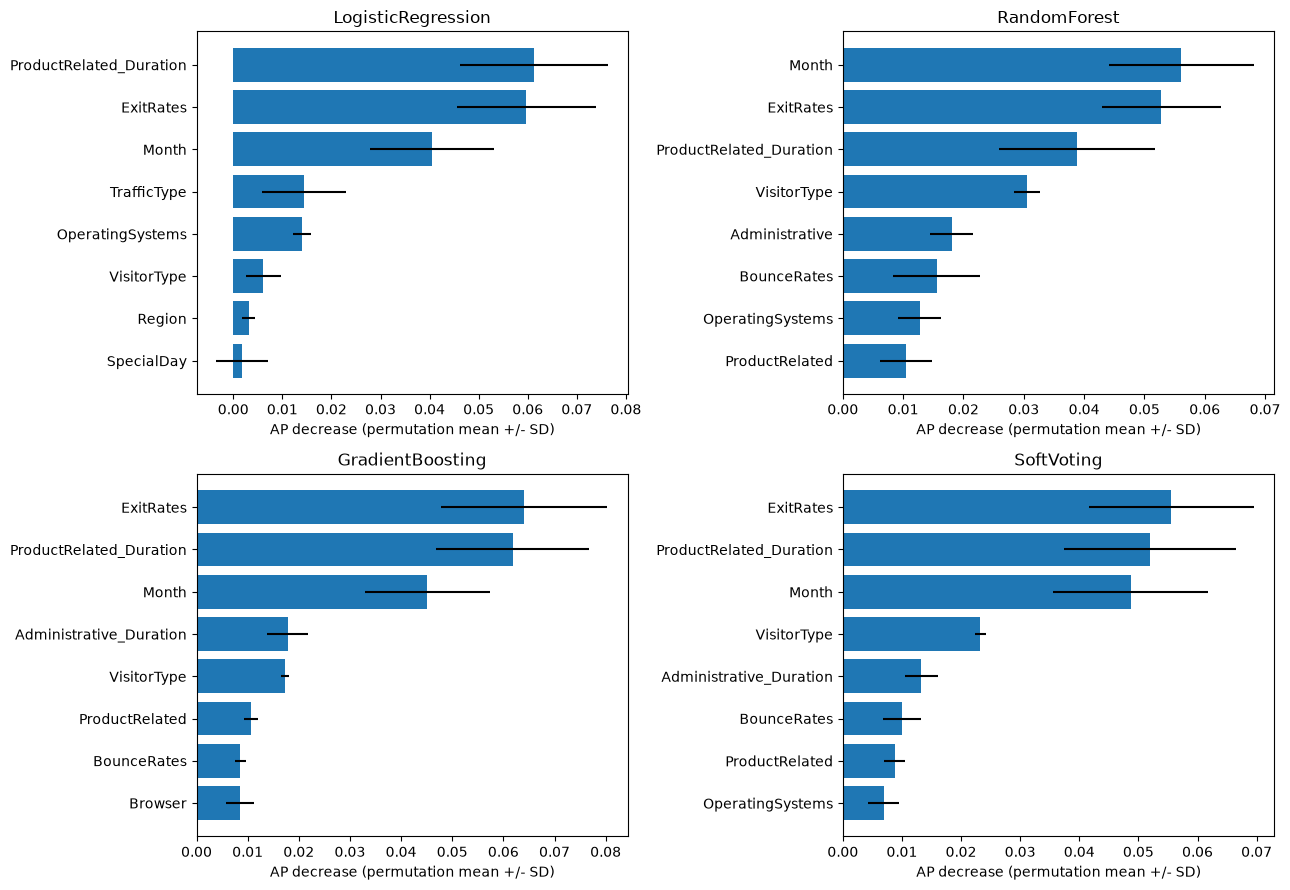

In [13]:
importance_rows = []
for model_name, model in models.items():
    result = permutation_importance(
        model, test_features, test_target, scoring='average_precision',
        n_repeats=PERMUTATION_REPEATS, random_state=RANDOM_SEED, n_jobs=1)
    for column_number, column in enumerate(test_features.columns):
        importance_rows.append({
            'model': model_name, 'feature': column,
            'mean_ap_decrease': result.importances_mean[column_number],
            'sd_ap_decrease': result.importances_std[column_number]})
importance_table = pd.DataFrame(importance_rows)
with pd.option_context('display.max_rows', None, 'display.precision', 4):
    display(importance_table)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, model_name in zip(axes.flat, models):
    model_rows = importance_table[importance_table['model'] == model_name]
    top_features = model_rows.nlargest(8, 'mean_ap_decrease').sort_values('mean_ap_decrease')
    ax.barh(top_features['feature'], top_features['mean_ap_decrease'], xerr=top_features['sd_ap_decrease'])
    ax.set_title(model_name)
    ax.set_xlabel('AP decrease (permutation mean +/- SD)')
fig.tight_layout()
plt.show()

## 4.9 Deployment recommendation
Keep **Random Forest** as the candidate for further validation. It has better observed AP than the vote and needs one component. The ensemble difference interval crosses zero, so do not claim a statistically certain disadvantage or equivalence.

Recall at 0.50 is low: the forest finds 20 of 382 purchases. A useful ranking is not a validated intervention policy. Check when inputs are available, whether scores match real purchase rates (calibration), the costs of mistakes, the decision threshold and performance on newer traffic. PageValues availability remains uncertain; other full-session inputs also need timing checks.

In [14]:
boot = bootstrap
recommendation = STRONGEST_BASE
if boot['ci_lower'] > 0 and boot['observed_ap_difference'] >= 0.01:
    recommendation = 'SoftVoting'
recommendation_details = dict(model=recommendation,
    rule='Prefer ensemble only if its AP gain is >= 0.01 and paired 95% interval is wholly positive; otherwise prefer CV-strongest individual.',
    note='A practical reporting judgement, not a threshold for statistical significance or a business cost model.')
print('Recommended candidate:', recommendation)
print('Ensemble minus RF AP:', boot['observed_ap_difference'])
print('Paired 95% interval:', boot['ci_lower'], boot['ci_upper'])
display(pd.Series(recommendation_details, name="Recommendation"))

Recommended candidate: RandomForest
Ensemble minus RF AP: -0.013599019310164884
Paired 95% interval: -0.025197799234584862 0.0008840332804211924


model                                         RandomForest
rule     Prefer ensemble only if its AP gain is >= 0.01...
note     A practical reporting judgement, not a thresho...
Name: Recommendation, dtype: str